In [53]:
import sys
# from opentrons import protocol_api, execute, simulate
# from opentrons.types import Location, Point
import pandas as pd
import numpy as np
import random
import requests
import ast  # safer than eval
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import cv2
import json
import seaborn as sns

import asyncio
import websockets
import base64
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPythonImage
from ipywidgets import interact, IntSlider, fixed
from IPython.display import display, HTML
from color_mixing import GaussianProcess, BayesianOptimization, MaraData

# Calibrate Image


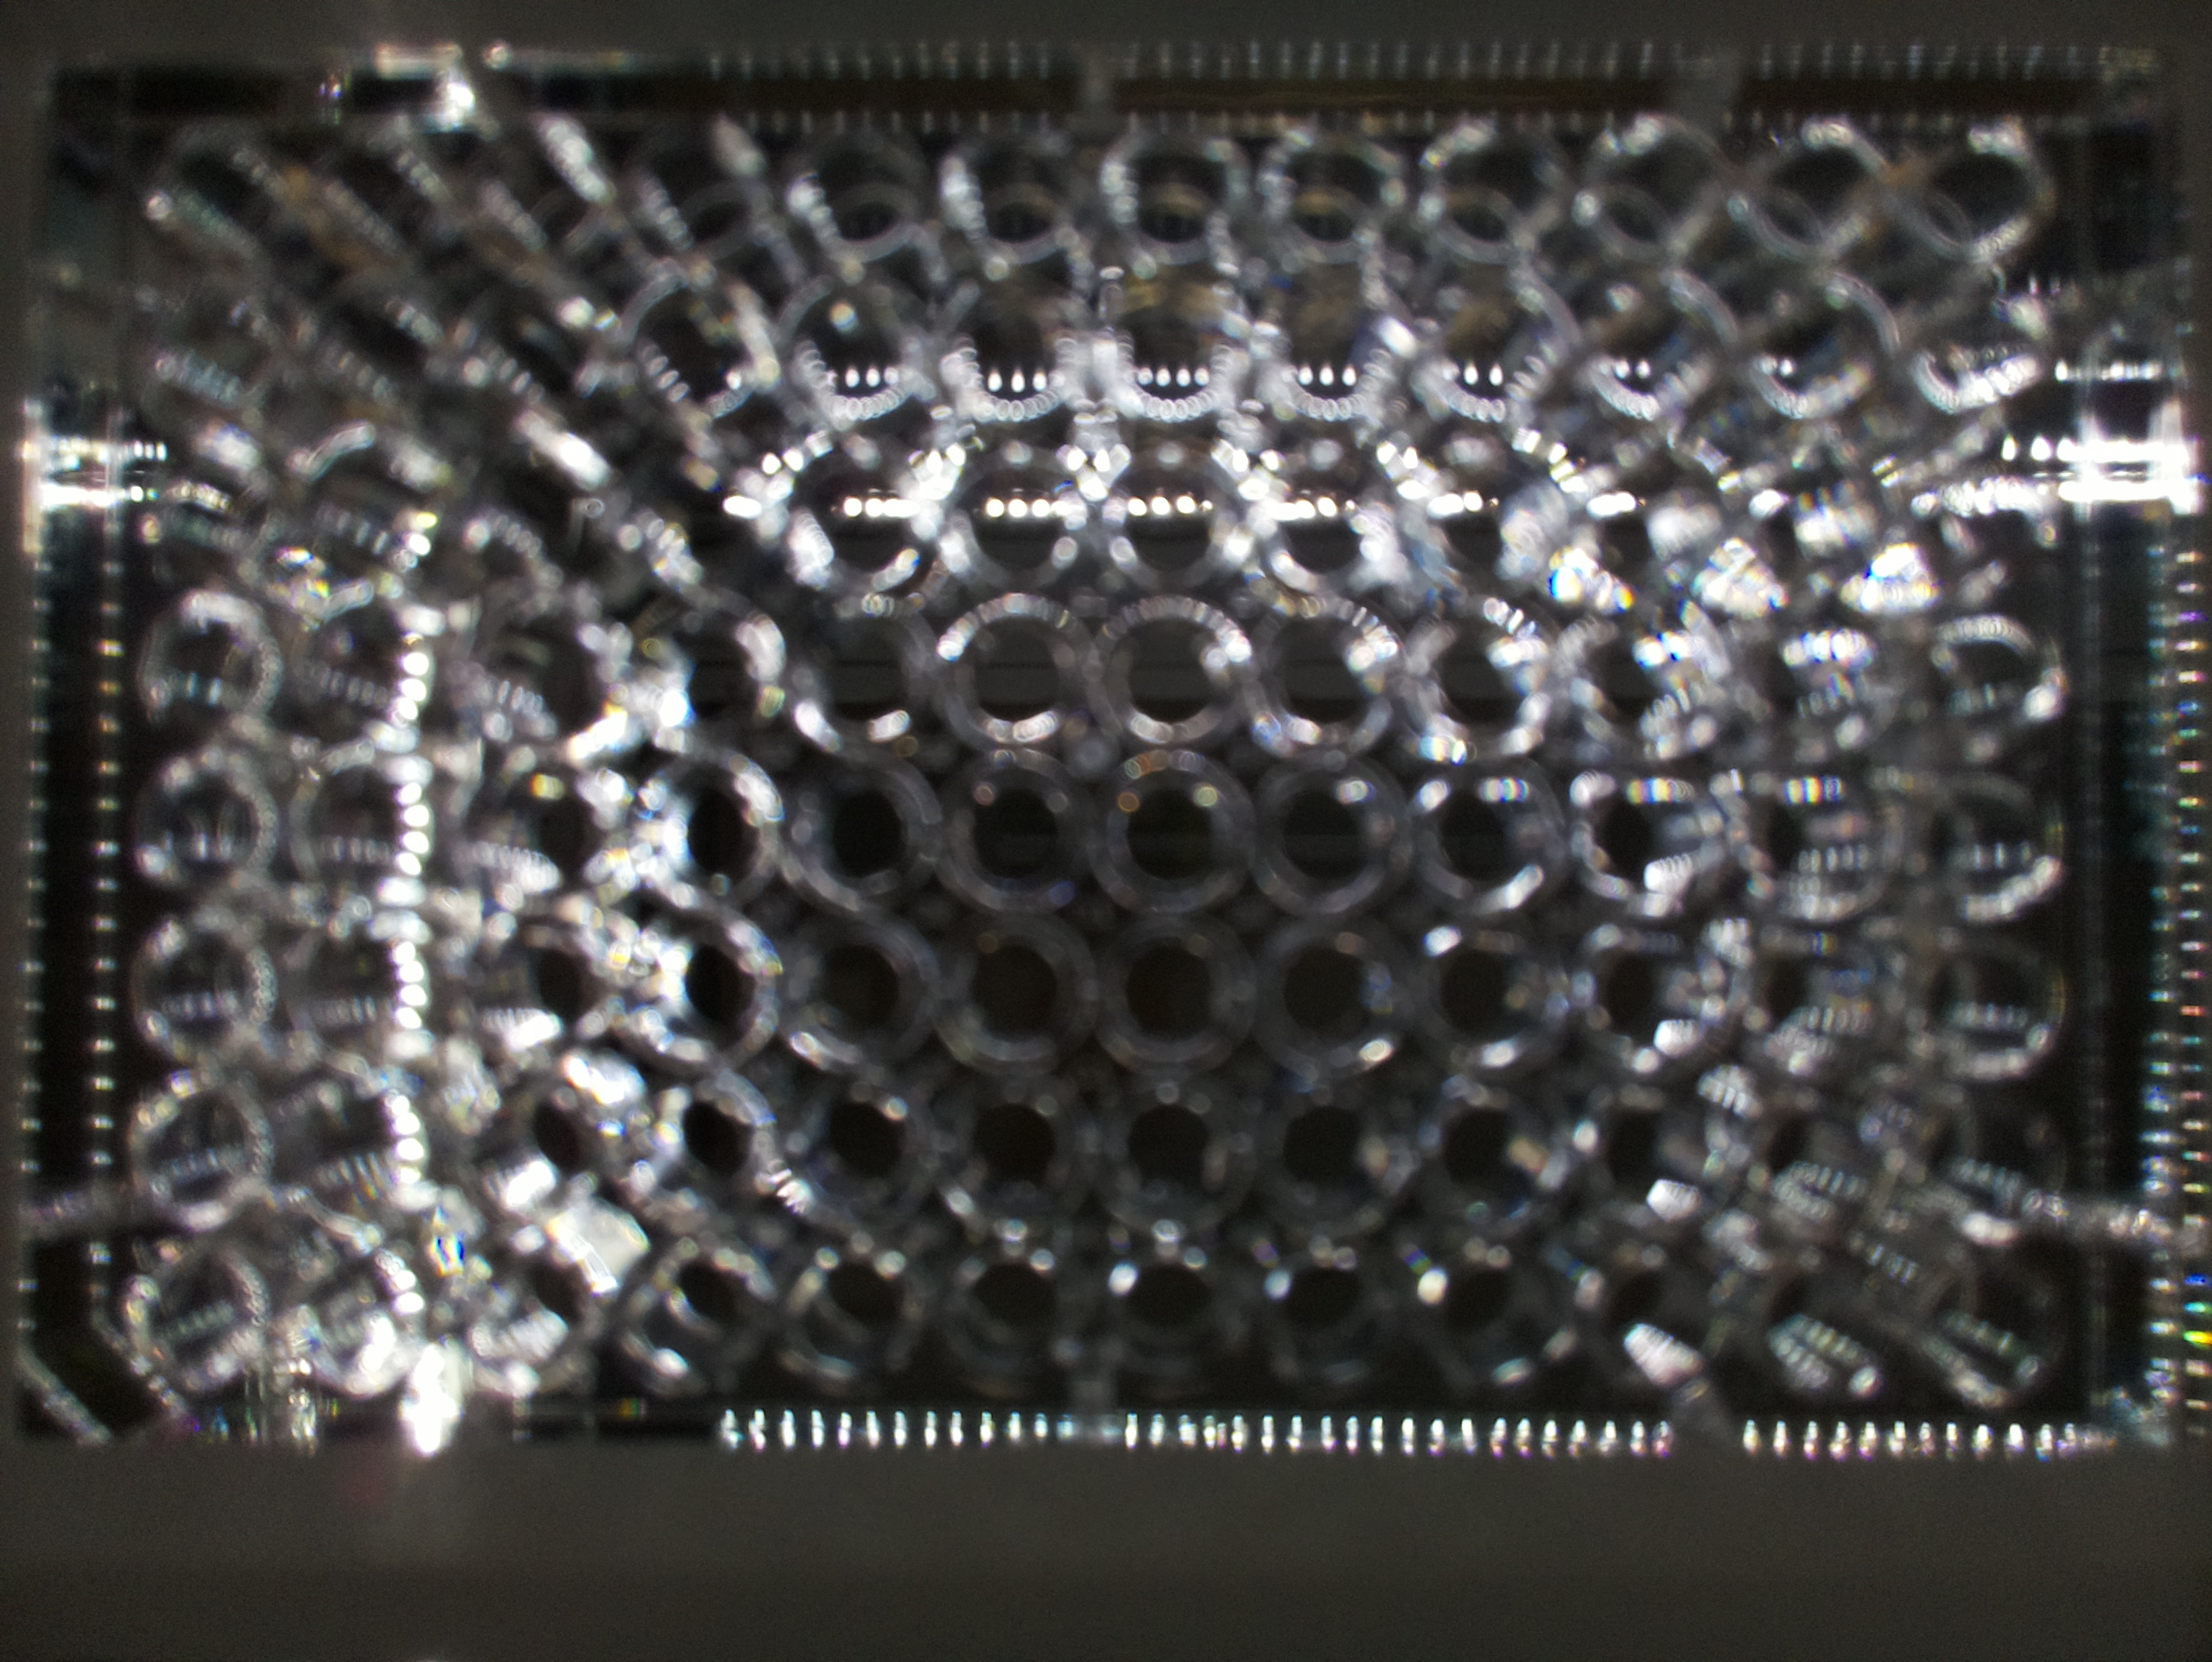

Image captured
Image saved .jpg
None


In [64]:
async def capture_photo(counter):
    uri = "ws://172.28.236.86:8765"
    
    async with websockets.connect(uri, max_size=5_000_000) as websocket:
        # send command to capture
        await websocket.send("capture")
        
        # wait for response
        response = await websocket.recv()
        
        try:
            # decode from Base64
            img_data = base64.b64decode(response)
            
            display(IPythonImage(data=img_data, format='jpg'))
            print("Image captured")

            with open(f"images/{counter}.jpg", "wb") as f:
                f.write(img_data)
            print("Image saved .jpg")

        except Exception as e:
            print("Response:", response)
            print("Exception:", e)

result = await capture_photo(counter=0)
print(result)


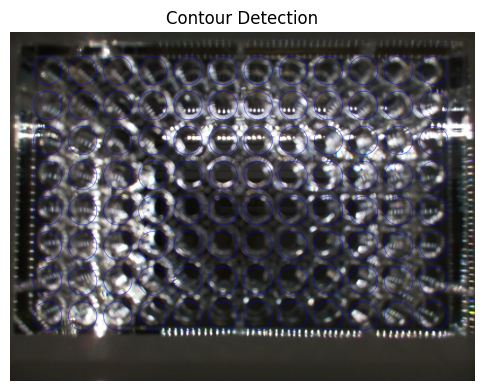

In [65]:
counter = 0
image_path = f"images/{counter}.jpg"
# parameters for bilateral filtering
diameter = 5
sigmaColor = 75
sigmaSpace = 75

image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

rows = 8
cols = 12

# define coordinates for top-left and bottom-right grid points
top_left = (265, 278)
bottom_right = (2989, 2006)

x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

expected_grid = []
rgb_values = []

for row in range(rows):
    for col in range(cols):
        x = int(top_left[0] + col * x_step)
        y = int(top_left[1] + row * y_step)
        expected_grid.append((x, y))
        
        # image[row, col] → image[y, x]
        b, g, r = image_rgb[y, x]  
        rgb_values.append([r, g, b]) 

output_grid = image_rgb.copy()

# draw circle
for (x, y) in expected_grid:
    cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(output_grid_rgb)
plt.axis("off")
plt.title("Contour Detection")
plt.show()


background subtration

1st well: [48, 50, 47]
2nd well: [52, 55, 64]


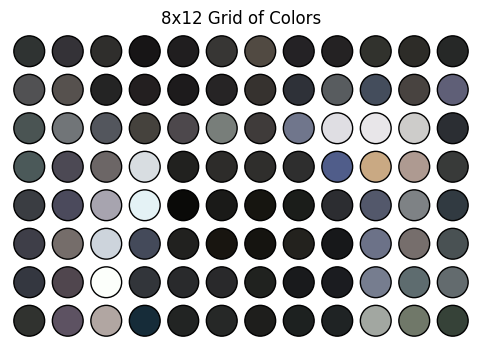

In [66]:
fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print('1st well:', rgb_values[84])
print('2nd well:', rgb_values[72])

ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()


# Generate 5 samples as training data

In [68]:
from pyDOE import lhs

# Number of samples
num_samples = 8

np.random.seed(42)  # Set seed for reproducibility
# Generate 5D Latin Hypercube Sampling
lhs_samples = lhs(4, samples=num_samples)

# Convert to volumes
lhs_samples_volumes = lhs_samples / lhs_samples.sum(axis=1, keepdims=True) * 250

# Convert lhs_samples_volumes to a DataFrame
lhs_df = pd.DataFrame(lhs_samples_volumes, columns=["volC", "volM", "volY", "volK"]).round(1)
lhs_df

,volC,volM,volY,volK
0,55.6,87.7,68.4,38.4
1,46.4,57.3,135.7,10.7
2,123.9,44.2,11.9,70.0
3,76.6,70.1,14.4,88.9
4,7.6,92.1,41.1,109.2
5,42.6,78.4,49.3,79.7
6,34.1,28.1,93.9,93.9
7,102.9,18.4,98.9,29.8


In [75]:
# Define Counter
counter = 1

# Increments of a 96 well plate
cell = [f"{chr(col)}{row}" for col in range(ord('A'), ord('H') + 1) for row in range(1, 13)]
# Generate IDs and wells for the new samples
lhs_df["id"] = range(counter, counter + len(lhs_df))
lhs_df["well"] = cell[counter-1::12][:len(lhs_df)]

# Reorder columns to match the existing CSV structure
lhs_df = lhs_df[["id", "well", "volC", "volM", "volY", "volK"]]

# csv_path = "opentron_shared/conditions.csv"
csv_save = "opentron_shared/conditions_save.csv"
# Save the updated DataFrame to the CSV files
# lhs_df.to_csv(csv_path, index=False)
# lhs_df.to_csv(csv_save, mode='a', header=False, index=False)
lhs_df

,id,well,volC,volM,volY,volK
0,1,A1,55.6,87.7,68.4,38.4
1,2,B1,46.4,57.3,135.7,10.7
2,3,C1,123.9,44.2,11.9,70.0
3,4,D1,76.6,70.1,14.4,88.9
4,5,E1,7.6,92.1,41.1,109.2
5,6,F1,42.6,78.4,49.3,79.7
6,7,G1,34.1,28.1,93.9,93.9
7,8,H1,102.9,18.4,98.9,29.8


># Mara --> Sample lhs_data in Mara
## Run this in terminal on Shared Folder

```
cd: Mara_shared
python -m http.server 8000
```

This will open a sever to allow opentron to acess the file from: 

csv_path = "http://192.168.0.100:8000/conditions.csv"   if on Mara Laptop\
local_path = "http://127.0.0.1:8000/conditions.csv" if on local Laptop

# Capture Image and convert to RGB

In [ ]:
result = await capture_photo()
print(result)

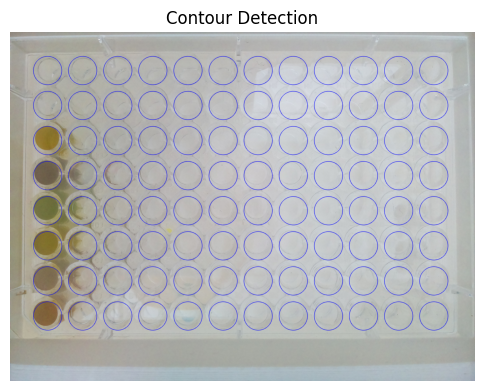

In [56]:
def image_rgb_extraction(image_path):
    # parameters for bilateral filtering
    diameter = 5
    sigmaColor = 75
    sigmaSpace = 75

    image_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    filtered_image = cv2.bilateralFilter(image_gray, diameter, sigmaColor, sigmaSpace)
    image_rgb = cv2.imread(image_path)

    rows = 8
    cols = 12

    # define coordinates for top-left and bottom-right grid points
    top_left = (265, 278)
    bottom_right = (2989, 2006)

    x_step = (bottom_right[0] - top_left[0]) / (cols - 1)
    y_step = (bottom_right[1] - top_left[1]) / (rows - 1)

    expected_grid = []
    new_rgb_values = []

    for row in range(rows):
        for col in range(cols):
            x = int(top_left[0] + col * x_step)
            y = int(top_left[1] + row * y_step)
            expected_grid.append((x, y))
            
            # image[row, col] → image[y, x]
            b, g, r = image_rgb[y, x]  
            new_rgb_values.append([r, g, b]) 

    output_grid = image_rgb.copy()

    # draw circle
    for (x, y) in expected_grid:
        cv2.circle(output_grid, (x, y), 100, (255, 0, 0), 2)

    output_grid_rgb = cv2.cvtColor(output_grid, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(output_grid_rgb)
    plt.axis("off")
    plt.title("Contour Detection")
    plt.show()

    return new_rgb_values
    
#image_path = f'images/{counter}.jpg'
image_path = 'images/captured.jpg'
new_rgb_values = image_rgb_extraction(image_path)

[132, 100, 61]


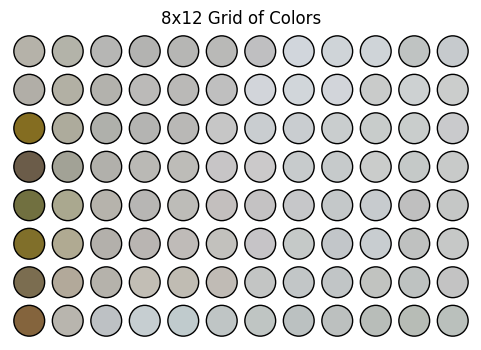

In [57]:
fig, ax = plt.subplots(figsize=(6, 4))

# make sure to have exact number of rows and columns
if len(rgb_values) < rows * cols:
    new_rgb_values += [[0, 0, 0]] * (rows * cols - len(new_rgb_values))

for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = new_rgb_values[index]
        # normalize RGB values to [0, 1]
        color = [val / 255 for val in rgb]
        # note the y-coordinate is inverted for display.
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, facecolor=color, 
                            edgecolor='black', linewidth=1)
        ax.add_patch(circle)

print(new_rgb_values[84])

# print(rgb_values)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off') 
plt.title('8x12 Grid of Colors')
plt.show()


In [58]:
def objective(rgb_list):
    target_rgb = np.array([129, 130, 117])  # Example target RGB
    rgb_list = np.array(rgb_list)
    return np.linalg.norm(rgb_list - target_rgb, axis=1)


test_list = new_rgb_values[0::12]

rgb_color = test_list[3]
color_hex = f"#{rgb_color[0]:02x}{rgb_color[1]:02x}{rgb_color[2]:02x}"

display(HTML(f'<div style="width:100px; height:50px; background-color:{color_hex};"></div>'))
print("RGB:", rgb_color)

RGB: [107, 92, 73]


# Start of Color Iterations!


In [63]:
# Set up the training data and bounds
train_x = lhs_df[["volC", "volM", "volY", "volK"]].values
train_y = objective(new_rgb_values[:5]).reshape(-1, 1)
og_bounds = np.array([[0, 250], [0, 250], [0, 250], [0, 250]])

### Step 1:  Genearte new conditions with GP + BO

In [ ]:
# make a gaussian process model
gp_model = GaussianProcess(train_X=train_x, train_Y=train_y, bounds=og_bounds)
gp_model.fit()
# run the optimization to get new conditions
bo = BayesianOptimization(gp_model, og_bounds, batch_size=8, seed = 42)
bo.suggest_next_point()
Conditions = bo.get_volume_df()
print(Conditions)


array([[ 23.9,  60.6,  46.6, 118.9],
       [103.8,  31.3,  28.7,  86.2],
       [ 23. ,  53.8,  88. ,  85.2],
       [ 71.8,  75.5,  53.1,  49.6],
       [ 77.1,  95.2,  59.9,  17.7]])

### Step 2: Add the new color into the CSV file and run Mara
>-  Prompt Mara to Start:  New row added
>-  Prompt Mara to Stop:  "ID" == exit


In [ ]:
# MUST UPDATE COUNTER
counter = 2

In [ ]:
next_condition = Conditions

# Generate IDs and wells for the new samples
next_condition["id"] = range(counter, counter + len(lhs_df))
next_condition["well"] = cell[counter-1::12][:len(lhs_df)]

# Reorder columns to match the existing CSV structure
df_save =  next_condition[["id", "well", "volC", "volM", "volY", "volK"]]

df_save.to_csv(csv_save, mode='a', header = False, index=False)

### Mara will automatically run when a new conditions is added

### Step 3: Capture next image once Mara is finished

In [ ]:
result = await capture_photo(counter)
print(result)

TypeError: capture_photo() missing 1 required positional argument: 'counter'

### Step 4: Extract the new RGB values and update the training data

In [ ]:
new_rgb_values = image_rgb_extraction(f'images/{counter}.jpg')
newest_rgb_values = new_rgb_values[counter::12]

train_x = np.concatenate((train_x, next_condition), axis=0)
train_y = np.concatenate((train_y, objective(new_rgb_values).reshape(-1, 1)), axis=0)

### Step 5: Iterate! 
- update teh counter and Run Step 1 trought 5 until target reached